# F8 : Battre la marche aléatoire (S&P 500)

**Nom et prénom :** MALAK SABRI · **Code Apogée :** 24010191 · **Groupe :** FIN 3 · **Filière :** FINANCE · **Date :** 24/11/2026
**Dépôt GitHub : https://github.com/malaksabri65/24010191-SABRI-FIN3.git
**Algorithme principal :** n° 8, régression logistique · **Comparaison :** n° 12, forêt aléatoire · **Données :** S&P 500, FRED

Ce notebook reprend l'étude de cas modèle (UCI 222) et l'applique au projet F8, dans le même ordre : introduction, état de l'art, travaux liés, données, exploration, préparation, algorithme, protocole, résultats, discussion, conclusion, références et annexes. Il télécharge lui-même les données : il suffit de lancer **Exécution > Tout exécuter**.

> **À propos des chiffres commentés.** Tous les commentaires chiffrés sont **calculés par le code** à partir de tes données au moment de l'exécution : aucun chiffre n'est écrit à la main. Les phrases s'adaptent aux résultats (critère atteint ou non).

**Sommaire**
0. Configuration · 1. Introduction · 2. État de l'art · 3. Travaux liés · 4. Jeu de données · 5. Exploration · 6. Préparation · 7. Algorithme · 8. Protocole expérimental · 9. Résultats · 10. Discussion · 11. Conclusion · 12. Références · 13. Annexes

## 0. Configuration

In [1]:
import platform, json, shutil
from datetime import date
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display
from scipy.stats import binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

GRAINE = 42
BASE = Path('projet_F08')
BASE.mkdir(exist_ok=True)
DATE_EXTRACTION = date.today().strftime('%d/%m/%Y')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})

def fr(x, d=1):
    # Nombre au format français (virgule décimale).
    return '{:.{d}f}'.format(x, d=d).replace('.', ',')

def dire(texte):
    display(Markdown(texte))

R = {}  # tous les résultats chiffrés, enregistrés à la fin
print('Python', platform.python_version(), '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Introduction

**Contexte.** Si les rendements d'un indice boursier suivent une marche aléatoire, aucune règle fondée sur les cours passés ne peut battre le hasard : c'est l'hypothèse d'efficience faible des marchés [2]. Un gérant, ou un étudiant en finance, veut savoir si les rendements et la volatilité récents permettent de prévoir le signe du lendemain, avant de bâtir une stratégie dessus.

**Problématique.** Un modèle de classification utilisant uniquement les rendements passés du S&P 500 prévoit-il le signe du rendement du jour suivant mieux que la référence naïve, sur une période de test postérieure à l'apprentissage ?

**Objectif mesurable (fixé avant de voir le test).** Métrique principale : accuracy sur le test (les 20 % de jours les plus récents). Réussite si l'accuracy dépasse d'au moins 2 points la meilleure des deux références (classe majoritaire de l'apprentissage ; signe de la veille) **et** si un test binomial unilatéral contre cette référence est significatif à 5 %. Métriques secondaires : F1 et AUC.

**Nature du problème.** Classification binaire sur série temporelle : la cible vaut 1 si le rendement du jour suivant est strictement positif, 0 sinon. Le découpage doit être chronologique.

## 2. État de l'art

Prédire le signe du rendement quotidien est un problème de classification où le signal est, par hypothèse, très faible. L'hypothèse d'efficience faible affirme que les cours passés n'apportent aucune information utile sur les cours futurs [2]. Plusieurs études ont cependant cherché des écarts à la marche aléatoire [3] et des variables capables de prévoir les rendements [4]. La régression logistique est la référence statistique pour modéliser une variable binaire [5]. La forêt aléatoire, moyenne de nombreux arbres de décision, capte des effets non linéaires et des interactions sans les spécifier [6]. Enfin, un modèle de série temporelle doit être évalué sur une période postérieure à celle de l'apprentissage, sinon l'information du futur contamine l'évaluation.

| Approche | Principe | Atouts | Limites | Réf. |
| --- | --- | --- | --- | --- |
| Marche aléatoire / efficience faible | Les rendements passés ne prédisent pas les rendements futurs | Cadre théorique clair, hypothèse testable | Hypothèse forte, discutée empiriquement | [2] |
| Règle naïve (signe de la veille) | Prévoir que demain aura le même signe qu'aujourd'hui | Aucune estimation, explicable | Ignore tout le reste de l'information | Cette étude |
| Régression logistique | Combinaison linéaire des variables, transformée en probabilité | Interprétable, robuste, peu de réglages | Effets linéaires sur la log-cote | [5] |
| Forêt aléatoire | Moyenne de nombreux arbres construits sur des échantillons aléatoires | Non-linéarités, interactions | Moins interprétable, risque de surapprentissage sur peu de signal | [6] |

## 3. Travaux liés

| Travail | Données | Méthode | Résultat principal | Différence avec cette étude |
| --- | --- | --- | --- | --- |
| Lo et MacKinlay, 1988 [3] | Rendements hebdomadaires d'indices boursiers américains, années 1960-1980 | Test du rapport de variances | Rejet de la marche aléatoire pour les indices hebdomadaires | Rendements quotidiens, classification du signe, période récente |
| Welch et Goyal, 2008 [4] | Séries américaines de long terme, nombreuses variables explicatives | Régressions de prévision, évaluation hors échantillon | Les prévisions hors échantillon sont décevantes et instables | Variables issues du seul prix ; horizon d'un jour |

**Positionnement.** Comme Welch et Goyal (2008), nous jugeons le modèle hors échantillon, sur une période postérieure à l'apprentissage. Notre étude est plus modeste : une seule série, des variables construites sur les seuls cours passés, un horizon d'un jour. Nos résultats ne sont donc pas directement comparables aux leurs.

*Vérifie ces deux références (résumés, dates, pages) avant de rendre : voir section 12.*

## 4. Jeu de données

### 4.1 Téléchargement depuis FRED

In [2]:
CHEMIN = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500'
try:
    brut = pd.read_csv(CHEMIN)
    print('Données téléchargées depuis FRED.')
except Exception as e:
    print('Téléchargement automatique impossible :', e)
    print('Importez le fichier CSV téléchargé sur FRED (série SP500) :')
    from google.colab import files
    up = files.upload()
    brut = pd.read_csv(list(up.keys())[0])

print('Dimensions brutes :', brut.shape)
print(brut.dtypes)
brut.head()

Données téléchargées depuis FRED.
Dimensions brutes : (2606, 2)
observation_date     object
SP500               float64
dtype: object


,observation_date,SP500
0,2016-11-25,2213.35
1,2016-11-28,2201.72
2,2016-11-29,2204.66
3,2016-11-30,2198.81
4,2016-12-01,2191.08


In [3]:
col_date = [c for c in brut.columns if c.lower() in ('observation_date', 'date')][0]
col_val = [c for c in brut.columns if c != col_date][0]
df = brut.rename(columns={col_date: 'date', col_val: 'prix'})
df['date'] = pd.to_datetime(df['date'])
df['prix'] = pd.to_numeric(df['prix'], errors='coerce')
n_manq = int(df['prix'].isna().sum())
pct_manq = float(df['prix'].isna().mean() * 100)
df = df.set_index('date').sort_index()
n_dup = int(df.index.duplicated().sum())
df = df.dropna()
R['n_manq'], R['pct_manq'], R['n_dup'] = n_manq, pct_manq, n_dup
R['n_brut'] = int(len(brut))
R['debut'], R['fin'] = str(df.index.min().date()), str(df.index.max().date())
print('Valeurs manquantes :', n_manq, '(' + fr(pct_manq, 2) + ' %) | doublons de dates :', n_dup)
print('Observations :', len(df), '| période :', R['debut'], '->', R['fin'])

Valeurs manquantes : 95 (3,65 %) | doublons de dates : 0
Observations : 2511 | période : 2016-11-25 -> 2026-11-20


### 4.2 Description

In [4]:
annees = (df.index.max() - df.index.min()).days / 365.25
krach = bool(df.index.min() <= pd.Timestamp('2020-03-01') and df.index.max() >= pd.Timestamp('2020-04-01'))
dire(f'''
- **Nom et source :** S&P 500, cours de clôture quotidiens, Federal Reserve Bank of St. Louis (FRED), série `SP500`, https://fred.stlouisfed.org/series/SP500
- **Date d'extraction :** {DATE_EXTRACTION} · **Licence :** données S&P Dow Jones Indices diffusées par FRED pour information ; usage ici strictement pédagogique (à confirmer sur la page « Notes » de la série).
- **Taille et fréquence :** {len(df)} observations quotidiennes (jours de bourse), du {R['debut']} au {R['fin']}, soit environ {fr(annees, 0)} ans.
- **Unité d'observation :** un jour de bourse.
- **Variable cible :** `y`, égale à 1 si le rendement du jour suivant est strictement positif, 0 sinon.
- **Adéquation :** la question porte sur la prévisibilité du signe du rendement quotidien ; la série des clôtures suffit à construire la cible et les variables passées.
- **Limites :** une seule série ; environ {fr(annees, 0)} ans de données, donc peu d'observations pour détecter un faible signal ; {'la période contient le krach de mars 2020 (régime de forte volatilité) ; ' if krach else ''}prix hors dividendes ; aucun coût de transaction.
''')


- **Nom et source :** S&P 500, cours de clôture quotidiens, Federal Reserve Bank of St. Louis (FRED), série `SP500`, https://fred.stlouisfed.org/series/SP500
- **Date d'extraction :** 24/11/2026 · **Licence :** données S&P Dow Jones Indices diffusées par FRED pour information ; usage ici strictement pédagogique (à confirmer sur la page « Notes » de la série).
- **Taille et fréquence :** 2511 observations quotidiennes (jours de bourse), du 2016-11-25 au 2026-11-20, soit environ 10 ans.
- **Unité d'observation :** un jour de bourse.
- **Variable cible :** `y`, égale à 1 si le rendement du jour suivant est strictement positif, 0 sinon.
- **Adéquation :** la question porte sur la prévisibilité du signe du rendement quotidien ; la série des clôtures suffit à construire la cible et les variables passées.
- **Limites :** une seule série ; environ 10 ans de données, donc peu d'observations pour détecter un faible signal ; la période contient le krach de mars 2020 (régime de forte volatilité) ; prix hors dividendes ; aucun coût de transaction.


### 4.3 Dictionnaire des variables

| Variable | Description | Type | Unité | Rôle | Manquants |
| --- | --- | --- | --- | --- | --- |
| `prix` | Cours de clôture du S&P 500 | numérique | points d'indice | brute | jours sans cotation retirés (section 4.1) |
| `ret` | Rendement logarithmique quotidien, 100 × ln(P_t / P_{t-1}) | numérique | % | base des variables | 1re ligne retirée |
| `ret_lag1` à `ret_lag5` | `ret` décalé de 1 à 5 jours | numérique | % | explicative | aucun après nettoyage |
| `moy5`, `moy20` | Moyenne glissante de `ret` sur 5 / 20 jours se terminant en t | numérique | % | explicative | aucun après nettoyage |
| `vol5`, `vol20` | Écart-type glissant de `ret` sur 5 / 20 jours se terminant en t | numérique | % | explicative | aucun après nettoyage |
| `y` | 1 si le rendement de t+1 est > 0, sinon 0 | binaire | sans | **cible** | dernière ligne retirée |

## 5. Exploration

### 5.1 Qualité des données et statistiques descriptives

In [5]:
df['ret'] = 100 * np.log(df['prix'] / df['prix'].shift(1))
r = df['ret'].dropna()
R['taux_hausse'] = float((r > 0).mean())
R['ret_moy'], R['ret_std'] = float(r.mean()), float(r.std())
R['ret_skew'], R['ret_kurt'] = float(r.skew()), float(r.kurt())
R['ret_min'], R['date_min'] = float(r.min()), str(r.idxmin().date())
R['ret_max'], R['date_max'] = float(r.max()), str(r.idxmax().date())
print('Part de jours haussiers :', fr(R['taux_hausse'] * 100), '%')
print('Pire jour :', fr(R['ret_min'], 2), '% le', R['date_min'], '| meilleur jour :', fr(R['ret_max'], 2), '% le', R['date_max'])
r.describe().round(3).to_frame('ret (%)').T

Part de jours haussiers : 54,6 %
Pire jour : -12,77 % le 2020-03-16 | meilleur jour : 9,09 % le 2025-04-09


,count,mean,std,min,25%,50%,75%,max
ret (%),2510.0,0.045,1.151,-12.765,-0.382,0.076,0.588,9.089


In [6]:
dire(f'''
**Lecture.** Après retrait des {n_manq} jours sans cotation ({fr(pct_manq, 2)} % des lignes brutes), il reste {len(df)} observations, sans doublon de date ({n_dup}). Les jours haussiers représentent {fr(R['taux_hausse'] * 100)} % des rendements : une règle qui prévoit toujours « hausse » a donc déjà une accuracy proche de ce chiffre, c'est ce que mesure la référence « classe majoritaire ». Le rendement quotidien moyen est de {fr(R['ret_moy'], 3)} % pour un écart-type de {fr(R['ret_std'], 2)} % : l'écart-type vaut {fr(R['ret_std'] / abs(R['ret_moy']), 0)} fois la moyenne (en valeur absolue), ce qui laisse peu de place à un signal. L'excès de kurtosis ({fr(R['ret_kurt'], 1)}) indique des queues épaisses : les jours extrêmes (le pire : {fr(R['ret_min'], 2)} % le {R['date_min']}) sont bien plus fréquents qu'avec une loi normale. Les valeurs extrêmes sont plausibles et sont conservées.
''')


**Lecture.** Après retrait des 95 jours sans cotation (3,65 % des lignes brutes), il reste 2511 observations, sans doublon de date (0). Les jours haussiers représentent 54,6 % des rendements : une règle qui prévoit toujours « hausse » a donc déjà une accuracy proche de ce chiffre, c'est ce que mesure la référence « classe majoritaire ». Le rendement quotidien moyen est de 0,045 % pour un écart-type de 1,15 % : l'écart-type vaut 25 fois la moyenne (en valeur absolue), ce qui laisse peu de place à un signal. L'excès de kurtosis (16,3) indique des queues épaisses : les jours extrêmes (le pire : -12,77 % le 2020-03-16) sont bien plus fréquents qu'avec une loi normale. Les valeurs extrêmes sont plausibles et sont conservées.


### 5.2 Graphiques

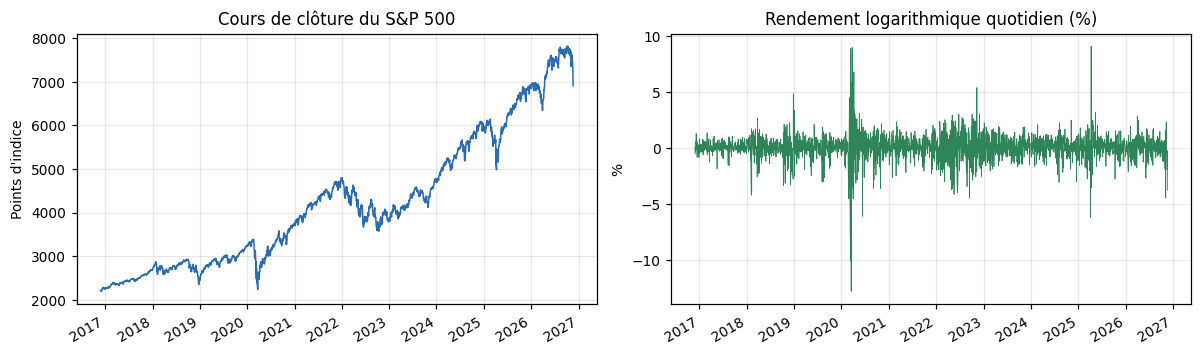

In [7]:
# Figure 1 : cours et rendements
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
df['prix'].plot(ax=ax[0], color='#2b6cb0', lw=1)
ax[0].set_title('Cours de clôture du S&P 500'); ax[0].set_xlabel(''); ax[0].set_ylabel('Points d\'indice')
df['ret'].plot(ax=ax[1], color='#2f855a', lw=0.5)
ax[1].set_title('Rendement logarithmique quotidien (%)'); ax[1].set_xlabel(''); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

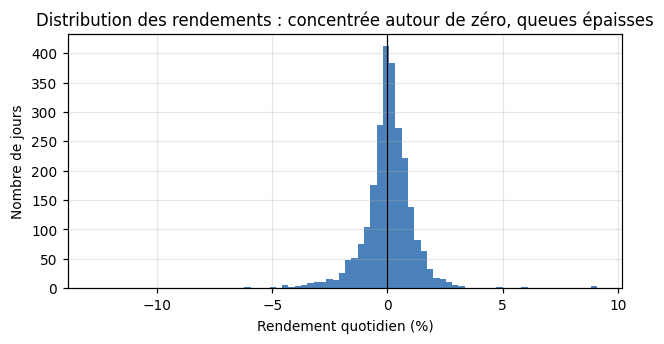

In [8]:
# Figure 2 : distribution des rendements
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(r, bins=80, color='#2b6cb0', alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Rendement quotidien (%)'); ax.set_ylabel('Nombre de jours')
ax.set_title('Distribution des rendements : concentrée autour de zéro, queues épaisses')
plt.show()

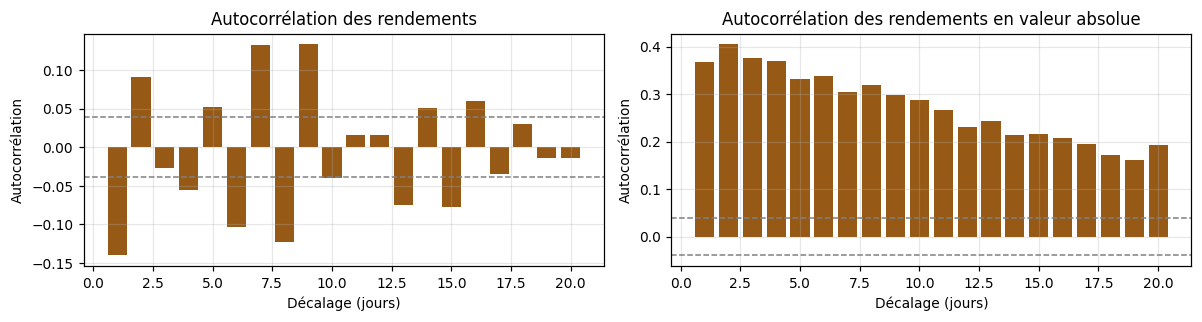

In [9]:
# Figure 3 : autocorrélation des rendements et de leur valeur absolue
lags = list(range(1, 21))
ac = [r.autocorr(l) for l in lags]
ac_abs = [r.abs().autocorr(l) for l in lags]
seuil_ac = 1.96 / np.sqrt(len(r))
R['ac1'] = float(ac[0]); R['seuil_ac'] = float(seuil_ac)
R['n_ac_sig'] = int(sum(abs(a) > seuil_ac for a in ac))
R['n_acabs_sig'] = int(sum(abs(a) > seuil_ac for a in ac_abs))
R['ac_abs1'] = float(ac_abs[0])

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a, vals, titre in [(ax[0], ac, 'Autocorrélation des rendements'), (ax[1], ac_abs, 'Autocorrélation des rendements en valeur absolue')]:
    a.bar(lags, vals, color='#975a16')
    a.axhline(seuil_ac, ls='--', color='grey', lw=1); a.axhline(-seuil_ac, ls='--', color='grey', lw=1)
    a.set_title(titre); a.set_xlabel('Décalage (jours)'); a.set_ylabel('Autocorrélation')
plt.tight_layout(); plt.show()

In [10]:
phrase_amp = ('l\'**amplitude** des mouvements est plus persistante que leur **signe** (volatilité par grappes).' if R['n_acabs_sig'] > R['n_ac_sig'] else 'ici, l\'amplitude des mouvements n\'apparaît pas nettement plus persistante que leur signe.')
dire(f'''
**Lecture des figures 1 à 3.** La figure 1 montre une série non stationnaire : le niveau du cours évolue fortement dans le temps et la variabilité des rendements change selon les périodes (des phases calmes, des phases agitées). La figure 3 compare les autocorrélations à la bande de ±{fr(seuil_ac, 3)} (seuil à 95 % sous l'hypothèse de bruit blanc). Pour les rendements, la corrélation avec la veille est de {fr(R['ac1'], 3)} et {R['n_ac_sig']} décalage(s) sur 20 dépassent la bande : c'est la mémoire linéaire dont dispose un modèle pour prévoir le signe. Pour les rendements en valeur absolue, {R['n_acabs_sig']} décalage(s) sur 20 dépassent la bande (corrélation d'ordre 1 : {fr(R['ac_abs1'], 3)}) : {phrase_amp} C'est pourquoi les variables `vol5` et `vol20` sont incluses.
''')


**Lecture des figures 1 à 3.** La figure 1 montre une série non stationnaire : le niveau du cours évolue fortement dans le temps et la variabilité des rendements change selon les périodes (des phases calmes, des phases agitées). La figure 3 compare les autocorrélations à la bande de ±0,039 (seuil à 95 % sous l'hypothèse de bruit blanc). Pour les rendements, la corrélation avec la veille est de -0,140 et 13 décalage(s) sur 20 dépassent la bande : c'est la mémoire linéaire dont dispose un modèle pour prévoir le signe. Pour les rendements en valeur absolue, 20 décalage(s) sur 20 dépassent la bande (corrélation d'ordre 1 : 0,367) : l'**amplitude** des mouvements est plus persistante que leur **signe** (volatilité par grappes). C'est pourquoi les variables `vol5` et `vol20` sont incluses.


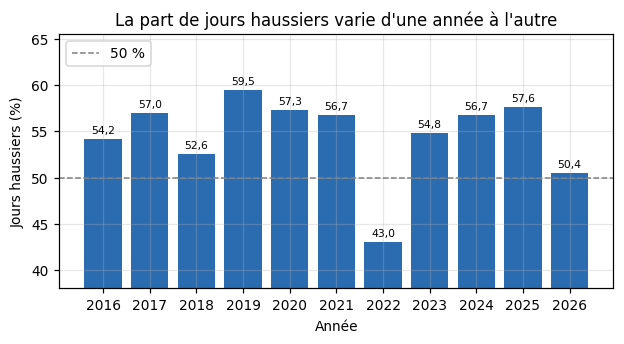

In [11]:
# Figure 4 : part de jours haussiers par année
par_an = r.groupby(r.index.year).apply(lambda s: (s > 0).mean() * 100)
R['hausse_par_an'] = {int(k): round(float(v), 1) for k, v in par_an.items()}
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar([str(a) for a in par_an.index], par_an.values, color='#2b6cb0')
ax.axhline(50, ls='--', color='grey', lw=1, label='50 %')
for i, v in enumerate(par_an.values):
    ax.text(i, v + 0.6, fr(v), ha='center', fontsize=7)
ax.set_ylim(min(par_an.min() - 5, 45), par_an.max() + 6)
ax.set_xlabel('Année'); ax.set_ylabel('Jours haussiers (%)')
ax.set_title('La part de jours haussiers varie d\'une année à l\'autre')
ax.legend(loc='upper left'); plt.show()

In [12]:
dire(f'''
**Lecture de la figure 4.** La part de jours haussiers va de {fr(par_an.min())} % ({int(par_an.idxmin())}) à {fr(par_an.max())} % ({int(par_an.idxmax())}). Elle n'est pas constante : la règle « toujours hausse » apprise sur le passé ne vaudra pas exactement la même chose sur la période de test. C'est une raison de plus pour un découpage chronologique.
''')


**Lecture de la figure 4.** La part de jours haussiers va de 43,0 % (2022) à 59,5 % (2019). Elle n'est pas constante : la règle « toujours hausse » apprise sur le passé ne vaudra pas exactement la même chose sur la période de test. C'est une raison de plus pour un découpage chronologique.


## 6. Préparation

In [13]:
for k in range(1, 6):
    df[f'ret_lag{k}'] = df['ret'].shift(k)
df['moy5'] = df['ret'].rolling(5).mean()
df['moy20'] = df['ret'].rolling(20).mean()
df['vol5'] = df['ret'].rolling(5).std()
df['vol20'] = df['ret'].rolling(20).std()
df['y'] = (df['ret'].shift(-1) > 0).astype(int)
df = df.iloc[:-1]      # dernière ligne : lendemain inconnu
df = df.dropna()       # début de série : fenêtres glissantes incomplètes

X_cols = [f'ret_lag{k}' for k in range(1, 6)] + ['moy5', 'moy20', 'vol5', 'vol20']
R['n_utilisables'] = int(len(df))
R['taux_y'] = float(df['y'].mean())
print('Observations utilisables :', len(df))
print('Part de jours haussiers (y = 1) :', fr(df['y'].mean() * 100, 2), '%')
df[X_cols + ['y']].head()

Observations utilisables : 2490
Part de jours haussiers (y = 1) : 54,58 %


,ret_lag1,ret_lag2,ret_lag3,ret_lag4,ret_lag5,moy5,moy20,vol5,vol20,y
date,,,,,,,,,,
2016-12-23,-0.186472,-0.246035,0.363092,0.197319,-0.175217,0.050599,0.112666,0.259289,0.479179,1
2016-12-27,0.125090,-0.186472,-0.246035,0.363092,0.197319,0.056053,0.150237,0.263401,0.455260,0
2016-12-28,0.224592,0.125090,-0.186472,-0.246035,0.363092,-0.184398,0.101607,0.417007,0.506240,0
2016-12-29,-0.839166,0.224592,0.125090,-0.186472,-0.246035,-0.141059,0.113425,0.420248,0.499934,0
2016-12-30,-0.029339,-0.839166,0.224592,0.125090,-0.186472,-0.196722,0.107794,0.445443,0.506051,1


In [14]:
# Découpage chronologique : 80 % les plus anciens pour l'apprentissage, 20 % les plus récents pour le test
coupure = int(len(df) * 0.8)
train, test = df.iloc[:coupure], df.iloc[coupure:]
X_tr, y_tr = train[X_cols], train['y']
X_te, y_te = test[X_cols], test['y']
R['n_train'], R['n_test'] = int(len(train)), int(len(test))
R['taux_train'], R['taux_test'] = float(y_tr.mean()), float(y_te.mean())
R['periode_train'] = [str(train.index.min().date()), str(train.index.max().date())]
R['periode_test'] = [str(test.index.min().date()), str(test.index.max().date())]
print(f"Apprentissage : {len(train)} jours ({R['periode_train'][0]} -> {R['periode_train'][1]}), part de hausses {fr(R['taux_train'] * 100)} %")
print(f"Test          : {len(test)} jours ({R['periode_test'][0]} -> {R['periode_test'][1]}), part de hausses {fr(R['taux_test'] * 100)} %")

Apprentissage : 1992 jours (2016-12-23 -> 2024-11-22), part de hausses 54,8 %
Test          : 498 jours (2024-11-25 -> 2026-11-19), part de hausses 53,8 %


**Choix de préparation.**

1. **Nettoyage :** seuls les jours sans cotation sont retirés ; aucune valeur extrême n'est supprimée.
2. **Variables créées :** rendement logarithmique, 5 retards, moyennes et écarts-types glissants sur 5 et 20 jours. Toutes se terminent à la date t.
3. **Cible :** signe du rendement de t+1.
4. **Mise à l'échelle :** standardisation dans un `Pipeline` pour la régression logistique ; inutile pour les arbres de la forêt aléatoire.
5. **Découpage chronologique :** 80 % des jours les plus anciens pour l'apprentissage, 20 % des plus récents pour le test, sans mélange.

**Prévention des fuites.**

- ✔ Variables construites avec des données jusqu'à t seulement ; la cible est le seul élément qui regarde en t+1.
- ✔ Découpage chronologique, sans mélange aléatoire.
- ✔ Standardisation ajustée sur l'apprentissage seulement, dans un `Pipeline` (et dans chaque pli de validation).
- ✔ Réglage des hyperparamètres par validation chronologique **dans** l'apprentissage ; test utilisé une seule fois, à la fin.
- ✔ Dernière ligne (lendemain inconnu) et début de série (fenêtres incomplètes) retirés.

## 7. Algorithme

**Choix.** Algorithme 8 du support : régression logistique. Elle modélise la probabilité que le lendemain soit haussier comme une fonction logistique d'une combinaison linéaire des variables. Elle est interprétable (un coefficient par variable) et robuste quand le signal est faible. La forêt aléatoire (algorithme 12) sert de comparaison pour voir si des effets non linéaires apparaissent.

**Principe.** Pour un jour décrit par le vecteur de variables $x$ :

$$\hat{p}(x) = \frac{1}{1 + e^{-(\beta_0 + \beta^\top x)}}$$

où $\hat{p}(x)$ est la probabilité estimée que le rendement du lendemain soit positif, $\beta_0$ la constante et $\beta$ le vecteur des coefficients. On prévoit « hausse » si $\hat{p}(x) \ge 0{,}5$. Les coefficients sont estimés en minimisant la perte logistique, avec une pénalité $\ell_2$ dont la force dépend de $C$ (plus $C$ est petit, plus les coefficients sont contraints) [5].

La forêt aléatoire construit de nombreux arbres sur des échantillons aléatoires des données et des variables, puis moyenne leurs votes [6].

**Paramètres appris :** les coefficients $\beta$ (régression logistique) ; la structure des arbres (forêt aléatoire).

| Hyperparamètre | Rôle et effet attendu | Valeurs testées |
| --- | --- | --- |
| `C` (régression logistique) | Inverse de la force de régularisation : petit, coefficients contraints vers zéro | 0,01 ; 0,1 ; 1 ; 10 |
| `max_depth` (forêt) | Profondeur maximale des arbres : grande, plus d'interactions et plus de risque de surapprentissage | 2 ; 3 ; 5 |
| `min_samples_leaf` (forêt) | Taille minimale d'une feuille : grande, arbres plus lisses | 20 ; 50 |

## 8. Protocole expérimental

In [15]:
dire(f'''
| Ensemble | Période | Observations |
| --- | --- | --- |
| Apprentissage | 80 % les plus anciens : {R['periode_train'][0]} -> {R['periode_train'][1]} (part de hausses {fr(R['taux_train'] * 100)} %) | {R['n_train']} |
| Validation | `TimeSeriesSplit`, 5 plis chronologiques dans l'apprentissage | 5 plis |
| Test | 20 % les plus récents : {R['periode_test'][0]} -> {R['periode_test'][1]} (part de hausses {fr(R['taux_test'] * 100)} %) | {R['n_test']} |

- **Références naïves :** classe majoritaire de l'apprentissage ; signe de la veille (le signe du rendement d'aujourd'hui sert de prévision pour demain).
- **Validation :** réglage de `C` (4 valeurs) pour la régression logistique, de `max_depth` et `min_samples_leaf` (6 combinaisons) pour la forêt, métrique accuracy, validation chronologique.
- **Métrique principale :** accuracy. **Métriques secondaires :** F1 et AUC ROC. (Les classes sont proches de l'équilibre : l'accuracy est interprétable ici.)
- **Critère de réussite :** accuracy du modèle ≥ meilleure référence + 2 points **et** test binomial unilatéral contre cette référence significatif à 5 %.
- **Graine aléatoire :** {GRAINE}.
''')


| Ensemble | Période | Observations |
| --- | --- | --- |
| Apprentissage | 80 % les plus anciens : 2016-12-23 -> 2024-11-22 (part de hausses 54,8 %) | 1992 |
| Validation | `TimeSeriesSplit`, 5 plis chronologiques dans l'apprentissage | 5 plis |
| Test | 20 % les plus récents : 2024-11-25 -> 2026-11-19 (part de hausses 53,8 %) | 498 |

- **Références naïves :** classe majoritaire de l'apprentissage ; signe de la veille (le signe du rendement d'aujourd'hui sert de prévision pour demain).
- **Validation :** réglage de `C` (4 valeurs) pour la régression logistique, de `max_depth` et `min_samples_leaf` (6 combinaisons) pour la forêt, métrique accuracy, validation chronologique.
- **Métrique principale :** accuracy. **Métriques secondaires :** F1 et AUC ROC. (Les classes sont proches de l'équilibre : l'accuracy est interprétable ici.)
- **Critère de réussite :** accuracy du modèle ≥ meilleure référence + 2 points **et** test binomial unilatéral contre cette référence significatif à 5 %.
- **Graine aléatoire :** 42.


### 8.1 Références naïves

In [16]:
tscv = TimeSeriesSplit(n_splits=5)
plis = list(tscv.split(X_tr))

classe_maj = int(y_tr.mean() >= 0.5)
acc_maj = accuracy_score(y_te, np.full(len(y_te), classe_maj))
acc_veille = accuracy_score(y_te, (test['ret'] > 0).astype(int))   # signe d'aujourd'hui = prévision de demain
meilleure_ref = max(acc_maj, acc_veille)
nom_ref = 'classe majoritaire' if acc_maj >= acc_veille else 'signe de la veille'
R['acc_maj'], R['acc_veille'] = float(acc_maj), float(acc_veille)
R['meilleure_ref'], R['nom_ref'], R['classe_maj'] = float(meilleure_ref), nom_ref, classe_maj

# mêmes références sur les plis de validation
v_maj, v_veille = [], []
for a, v in plis:
    cm = int(y_tr.iloc[a].mean() >= 0.5)
    v_maj.append(accuracy_score(y_tr.iloc[v], np.full(len(v), cm)))
    v_veille.append(accuracy_score(y_tr.iloc[v], (train['ret'].iloc[v] > 0).astype(int)))
R['val_maj'] = [float(np.mean(v_maj)), float(np.std(v_maj))]
R['val_veille'] = [float(np.mean(v_veille)), float(np.std(v_veille))]

print(f"Classe majoritaire (classe {classe_maj}) : test {fr(acc_maj * 100, 2)} % | validation {fr(R['val_maj'][0] * 100, 2)} % ± {fr(R['val_maj'][1] * 100, 2)}")
print(f"Signe de la veille              : test {fr(acc_veille * 100, 2)} % | validation {fr(R['val_veille'][0] * 100, 2)} % ± {fr(R['val_veille'][1] * 100, 2)}")
print(f"Meilleure référence sur le test : {nom_ref} ({fr(meilleure_ref * 100, 2)} %)")
print(f"Seuil de réussite (référence + 2 points) : {fr(meilleure_ref * 100 + 2, 2)} %")

Classe majoritaire (classe 1) : test 53,82 % | validation 54,40 % ± 3,83
Signe de la veille              : test 51,61 % | validation 48,80 % ± 3,53
Meilleure référence sur le test : classe majoritaire (53,82 %)
Seuil de réussite (référence + 2 points) : 55,82 %


### 8.2 Réglage des hyperparamètres par validation chronologique

In [17]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rech_lr = GridSearchCV(lr, {'logisticregression__C': [0.01, 0.1, 1, 10]},
                       scoring='accuracy', cv=tscv, return_train_score=True)
rech_lr.fit(X_tr, y_tr)

rf = RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1)
rech_rf = GridSearchCV(rf, {'max_depth': [2, 3, 5], 'min_samples_leaf': [20, 50]},
                       scoring='accuracy', cv=tscv, return_train_score=True)
rech_rf.fit(X_tr, y_tr)

def tab_grille(rech, noms):
    res = pd.DataFrame(rech.cv_results_)
    t = res[['param_' + n for n in noms] + ['mean_test_score', 'std_test_score', 'mean_train_score']].copy()
    t.columns = [n.split('__')[-1] for n in noms] + ['acc_validation', 'ecart_type', 'acc_apprentissage']
    return t.round(4)

t_lr = tab_grille(rech_lr, ['logisticregression__C'])
t_rf = tab_grille(rech_rf, ['max_depth', 'min_samples_leaf'])
R['meilleur_lr'] = {k.split('__')[-1]: float(v) for k, v in rech_lr.best_params_.items()}
R['meilleur_rf'] = {k: int(v) for k, v in rech_rf.best_params_.items()}
R['val_lr'] = [float(rech_lr.best_score_), float(rech_lr.cv_results_['std_test_score'][rech_lr.best_index_])]
R['val_rf'] = [float(rech_rf.best_score_), float(rech_rf.cv_results_['std_test_score'][rech_rf.best_index_])]
print('Régression logistique, meilleure configuration :', R['meilleur_lr'])
print('Forêt aléatoire, meilleure configuration :', R['meilleur_rf'])
t_lr

Régression logistique, meilleure configuration : {'C': 0.01}
Forêt aléatoire, meilleure configuration : {'max_depth': 3, 'min_samples_leaf': 20}


,C,acc_validation,ecart_type,acc_apprentissage
0,0.01,0.5440,0.0365,0.5638
1,0.10,0.5307,0.0326,0.5718
2,1.00,0.5271,0.0308,0.5728
3,10.00,0.5283,0.0283,0.5728


In [18]:
t_rf.sort_values('acc_validation', ascending=False)

,max_depth,min_samples_leaf,acc_validation,ecart_type,acc_apprentissage
2,3,20,0.5434,0.0355,0.6106
0,2,20,0.5416,0.0345,0.5825
4,5,20,0.5398,0.0358,0.6622
5,5,50,0.5380,0.0293,0.6096
1,2,50,0.5373,0.0359,0.5765
3,3,50,0.5373,0.0328,0.5880


In [19]:
ecart_lr = t_lr['acc_validation'].max() - t_lr['acc_validation'].min()
ecart_rf = t_rf['acc_validation'].max() - t_rf['acc_validation'].min()
surapp_rf = float((t_rf['acc_apprentissage'] - t_rf['acc_validation']).max())
dire(f'''
**Lecture de la validation.** Pour la régression logistique, les 4 valeurs de `C` donnent des accuracy de validation qui ne diffèrent que de {fr(ecart_lr * 100, 2)} point(s) ; la meilleure est `C` = {R['meilleur_lr']['C']:g} (accuracy {fr(R['val_lr'][0] * 100, 2)} % ± {fr(R['val_lr'][1] * 100, 2)}). Pour la forêt, l'écart entre les 6 combinaisons est de {fr(ecart_rf * 100, 2)} point(s) ; la meilleure est `max_depth` = {R['meilleur_rf']['max_depth']} avec `min_samples_leaf` = {R['meilleur_rf']['min_samples_leaf']} (accuracy {fr(R['val_rf'][0] * 100, 2)} % ± {fr(R['val_rf'][1] * 100, 2)}). Pour comparaison, la classe majoritaire fait {fr(R['val_maj'][0] * 100, 2)} % ± {fr(R['val_maj'][1] * 100, 2)} en validation et le signe de la veille {fr(R['val_veille'][0] * 100, 2)} % ± {fr(R['val_veille'][1] * 100, 2)}. L'écart-type entre plis est du même ordre que les différences entre modèles : les écarts en validation sont à lire avec prudence. Le surapprentissage maximal de la forêt (accuracy d'apprentissage moins accuracy de validation) atteint {fr(surapp_rf * 100, 1)} points.
''')


**Lecture de la validation.** Pour la régression logistique, les 4 valeurs de `C` donnent des accuracy de validation qui ne diffèrent que de 1,69 point(s) ; la meilleure est `C` = 0.01 (accuracy 54,40 % ± 3,65). Pour la forêt, l'écart entre les 6 combinaisons est de 0,61 point(s) ; la meilleure est `max_depth` = 3 avec `min_samples_leaf` = 20 (accuracy 54,34 % ± 3,55). Pour comparaison, la classe majoritaire fait 54,40 % ± 3,83 en validation et le signe de la veille 48,80 % ± 3,53. L'écart-type entre plis est du même ordre que les différences entre modèles : les écarts en validation sont à lire avec prudence. Le surapprentissage maximal de la forêt (accuracy d'apprentissage moins accuracy de validation) atteint 12,2 points.


## 9. Résultats

Le jeu de test est utilisé **une seule fois**, ci-dessous.

In [20]:
mod_lr = rech_lr.best_estimator_     # réajusté sur tout l'apprentissage
mod_rf = rech_rf.best_estimator_

res = {}
for nom, m in [('lr', mod_lr), ('rf', mod_rf)]:
    p = m.predict(X_te)
    pr = m.predict_proba(X_te)[:, 1]
    n_ok = int((p == y_te.values).sum())
    res[nom] = {'pred': p, 'proba': pr, 'n_ok': n_ok,
                'acc': accuracy_score(y_te, p),
                'f1': f1_score(y_te, p, zero_division=0),
                'auc': roc_auc_score(y_te, pr),
                'p_val': binomtest(n_ok, len(y_te), p=meilleure_ref, alternative='greater').pvalue,
                'part_hausse_predite': float(p.mean())}

n_test = len(y_te)
acc, f1, auc, p_val = res['lr']['acc'], res['lr']['f1'], res['lr']['auc'], res['lr']['p_val']
critere = bool((acc >= meilleure_ref + 0.02) and (p_val < 0.05))
R['test'] = {nom: {k: float(v) for k, v in d.items() if k in ('acc', 'f1', 'auc', 'p_val', 'part_hausse_predite')} for nom, d in res.items()}
R['critere_atteint'] = critere
R['ecart_points'] = float((acc - meilleure_ref) * 100)

print(f"Régression logistique : accuracy {fr(acc * 100, 2)} % | F1 {fr(f1, 3)} | AUC {fr(auc, 3)}")
print(f"Écart vs meilleure référence : {R['ecart_points']:+.2f} points | p-valeur binomiale unilatérale : {p_val:.4f}")
print('CRITÈRE :', 'ATTEINT' if critere else 'NON ATTEINT')
print(f"Forêt aléatoire : accuracy {fr(res['rf']['acc'] * 100, 2)} % | F1 {fr(res['rf']['f1'], 3)} | AUC {fr(res['rf']['auc'], 3)} | p-valeur {res['rf']['p_val']:.4f}")

Régression logistique : accuracy 53,82 % | F1 0,695 | AUC 0,494
Écart vs meilleure référence : +0.00 points | p-valeur binomiale unilatérale : 0.5184
CRITÈRE : NON ATTEINT
Forêt aléatoire : accuracy 51,61 % | F1 0,677 | AUC 0,469 | p-valeur 0.8493


In [21]:
lignes = {'Référence : classe majoritaire': (acc_maj, None, None),
          'Référence : signe de la veille': (acc_veille, None, None),
          'Régression logistique (principal)': (acc, f1, auc),
          'Forêt aléatoire (comparaison)': (res['rf']['acc'], res['rf']['f1'], res['rf']['auc'])}
synthese = pd.DataFrame({
    'Accuracy test (%)': [fr(v[0] * 100, 2) for v in lignes.values()],
    'F1 test': ['' if v[1] is None else fr(v[1], 3) for v in lignes.values()],
    'AUC test': ['' if v[2] is None else fr(v[2], 3) for v in lignes.values()]},
    index=list(lignes.keys()))
synthese

,Accuracy test (%),F1 test,AUC test
Référence : classe majoritaire,"53,82",,
Référence : signe de la veille,"51,61",,
Régression logistique (principal),"53,82","0,695","0,494"
Forêt aléatoire (comparaison),"51,61","0,677","0,469"


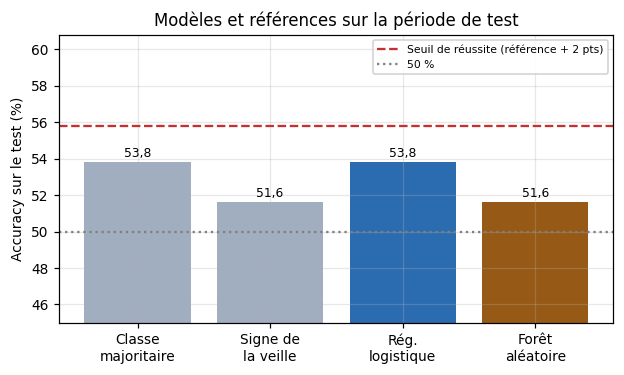

In [22]:
# Figure 5 : accuracy des modèles et des références sur le test
noms = ['Classe\nmajoritaire', 'Signe de\nla veille', 'Rég.\nlogistique', 'Forêt\naléatoire']
vals = [acc_maj * 100, acc_veille * 100, acc * 100, res['rf']['acc'] * 100]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(noms, vals, color=['#a0aec0', '#a0aec0', '#2b6cb0', '#975a16'])
ax.axhline(meilleure_ref * 100 + 2, ls='--', color='#c53030', label='Seuil de réussite (référence + 2 pts)')
ax.axhline(50, ls=':', color='grey', label='50 %')
for i, v in enumerate(vals):
    ax.text(i, v + 0.3, fr(v, 1), ha='center', fontsize=8)
ax.set_ylim(min(vals + [50]) - 5, max(vals + [meilleure_ref * 100 + 2]) + 5)
ax.set_ylabel('Accuracy sur le test (%)'); ax.set_title('Modèles et références sur la période de test')
ax.legend(fontsize=7, loc='upper right', framealpha=0.9); plt.show()

In [23]:
if critere:
    verdict = (f"Le critère est **atteint** : l'accuracy de la régression logistique ({fr(acc * 100, 2)} %) dépasse la meilleure référence ({nom_ref}, {fr(meilleure_ref * 100, 2)} %) de {fr(R['ecart_points'], 2)} points, et la p-valeur binomiale est de {fr(p_val, 4)}.")
else:
    raisons = []
    if acc < meilleure_ref + 0.02:
        raisons.append(f"l'écart de {fr(R['ecart_points'], 2)} points est inférieur aux 2 points exigés")
    if p_val >= 0.05:
        raisons.append(f"la p-valeur binomiale ({fr(p_val, 4)}) n'est pas inférieure à 5 %")
    verdict = (f"Le critère est **non atteint** : l'accuracy de la régression logistique ({fr(acc * 100, 2)} %) est comparée à la meilleure référence ({nom_ref}, {fr(meilleure_ref * 100, 2)} %) ; " + " et ".join(raisons) + ".")
dire(f'''
**Lecture des résultats.** Sur le test ({n_test} jours), la classe majoritaire donne {fr(acc_maj * 100, 2)} % et le signe de la veille {fr(acc_veille * 100, 2)} %. {verdict} L'AUC de la régression logistique vaut {fr(auc, 3)} (0,5 correspond au hasard) ; celle de la forêt aléatoire, {fr(res['rf']['auc'], 3)}, pour une accuracy de {fr(res['rf']['acc'] * 100, 2)} % (p-valeur {fr(res['rf']['p_val'], 4)}). La régression logistique prévoit « hausse » pour {fr(res['lr']['part_hausse_predite'] * 100)} % des jours du test, contre {fr(R['taux_test'] * 100)} % de hausses réelles.
''')


**Lecture des résultats.** Sur le test (498 jours), la classe majoritaire donne 53,82 % et le signe de la veille 51,61 %. Le critère est **non atteint** : l'accuracy de la régression logistique (53,82 %) est comparée à la meilleure référence (classe majoritaire, 53,82 %) ; l'écart de 0,00 points est inférieur aux 2 points exigés et la p-valeur binomiale (0,5184) n'est pas inférieure à 5 %. L'AUC de la régression logistique vaut 0,494 (0,5 correspond au hasard) ; celle de la forêt aléatoire, 0,469, pour une accuracy de 51,61 % (p-valeur 0,8493). La régression logistique prévoit « hausse » pour 97,6 % des jours du test, contre 53,8 % de hausses réelles.


In [24]:
# Analyse des erreurs : matrice de confusion et stabilité dans le temps (régression logistique)
p_lr = res['lr']['pred']
cm = confusion_matrix(y_te, p_lr, labels=[0, 1])
R['confusion'] = {'VN': int(cm[0, 0]), 'FP': int(cm[0, 1]), 'FN': int(cm[1, 0]), 'VP': int(cm[1, 1])}
cm_df = pd.DataFrame(cm, index=['Réel : baisse', 'Réel : hausse'], columns=['Prévu : baisse', 'Prévu : hausse'])

moitie = len(y_te) // 2
yt = y_te.values
acc_m1 = float(accuracy_score(yt[:moitie], p_lr[:moitie])); acc_m2 = float(accuracy_score(yt[moitie:], p_lr[moitie:]))
maj_m1 = float((yt[:moitie] == classe_maj).mean()); maj_m2 = float((yt[moitie:] == classe_maj).mean())
R['moities'] = {'lr': [acc_m1, acc_m2], 'maj': [maj_m1, maj_m2]}
marge = 1.96 * np.sqrt(0.25 / n_test)
R['marge_95'] = float(marge)
print('Matrice de confusion (régression logistique, test) :')
display(cm_df)
print(f"Accuracy 1re moitié du test : {fr(acc_m1 * 100)} % (classe majoritaire : {fr(maj_m1 * 100)} %)")
print(f"Accuracy 2e moitié du test  : {fr(acc_m2 * 100)} % (classe majoritaire : {fr(maj_m2 * 100)} %)")
print(f"Marge d'erreur à 95 % d'une accuracy mesurée sur {n_test} jours : ± {fr(marge * 100, 1)} points")

Matrice de confusion (régression logistique, test) :


,Prévu : baisse,Prévu : hausse
Réel : baisse,6,224
Réel : hausse,6,262


Accuracy 1re moitié du test : 56,6 % (classe majoritaire : 56,6 %)
Accuracy 2e moitié du test  : 51,0 % (classe majoritaire : 51,0 %)
Marge d'erreur à 95 % d'une accuracy mesurée sur 498 jours : ± 4,4 points


In [25]:
dire(f'''
**Analyse des erreurs.** Sur {n_test} jours, le modèle compte {R['confusion']['VP']} hausses bien prévues, {R['confusion']['VN']} baisses bien prévues, {R['confusion']['FP']} fausses hausses et {R['confusion']['FN']} hausses manquées. Son accuracy est de {fr(acc_m1 * 100)} % sur la première moitié du test et de {fr(acc_m2 * 100)} % sur la seconde ; la classe majoritaire fait respectivement {fr(maj_m1 * 100)} % et {fr(maj_m2 * 100)} %. La performance dépend donc de la sous-période. Avec seulement {n_test} jours de test, une accuracy mesurée a une marge d'erreur à 95 % d'environ ± {fr(marge * 100, 1)} points : un écart de 2 points avec la référence est du même ordre que le simple bruit d'échantillonnage.
''')


**Analyse des erreurs.** Sur 498 jours, le modèle compte 262 hausses bien prévues, 6 baisses bien prévues, 224 fausses hausses et 6 hausses manquées. Son accuracy est de 56,6 % sur la première moitié du test et de 51,0 % sur la seconde ; la classe majoritaire fait respectivement 56,6 % et 51,0 %. La performance dépend donc de la sous-période. Avec seulement 498 jours de test, une accuracy mesurée a une marge d'erreur à 95 % d'environ ± 4,4 points : un écart de 2 points avec la référence est du même ordre que le simple bruit d'échantillonnage.


In [26]:
# Coefficients de la régression logistique (variables standardisées)
coefs = mod_lr.named_steps['logisticregression'].coef_[0]
imp = pd.DataFrame({'variable': X_cols, 'coefficient': coefs, 'valeur_absolue': np.abs(coefs)})
imp = imp.sort_values('valeur_absolue', ascending=False).round(4)
R['coefficients'] = imp.head(5)[['variable', 'coefficient']].to_dict(orient='records')
imp[['variable', 'coefficient']].reset_index(drop=True)

,variable,coefficient
0,moy5,-0.0781
1,vol5,-0.0711
2,ret_lag5,-0.0626
3,ret_lag1,0.0510
4,ret_lag2,0.0182
5,moy20,-0.0170
6,ret_lag4,-0.0099
7,ret_lag3,0.0092
8,vol20,-0.0069


In [27]:
top = imp.iloc[0]
dire(f'''
**Coefficients.** Les variables étant standardisées, les coefficients sont comparables entre eux. Le plus grand en valeur absolue est celui de `{top['variable']}` ({fr(top['coefficient'], 3)}) ; une variation d'un écart-type de cette variable modifie la log-cote de hausse de {fr(abs(top['coefficient']), 3)}. Ce sont des associations statistiques, pas des relations de cause à effet, et des coefficients proches de zéro sont attendus quand le signal est faible.
''')


**Coefficients.** Les variables étant standardisées, les coefficients sont comparables entre eux. Le plus grand en valeur absolue est celui de `moy5` (-0,078) ; une variation d'un écart-type de cette variable modifie la log-cote de hausse de 0,078. Ce sont des associations statistiques, pas des relations de cause à effet, et des coefficients proches de zéro sont attendus quand le signal est faible.


## 10. Discussion des résultats

In [28]:
if critere:
    interp = (f"Le modèle fait mieux que le hasard informé de la référence {nom_ref} sur cette période de test. Ce résultat est à confirmer : il repose sur une seule période de {n_test} jours, et une accuracy supérieure ne dit rien de la rentabilité d'une stratégie une fois les coûts de transaction pris en compte.")
    litt = "Il va dans le sens des travaux qui trouvent un écart à la marche aléatoire [3], mais pas dans celui de [4], qui trouve une prévisibilité fragile hors échantillon : il faut le vérifier sur d'autres périodes avant de conclure."
else:
    interp = (f"Le modèle ne fait pas mieux que la référence {nom_ref} de façon convaincante sur cette période de test : les rendements et la volatilité passés ne permettent pas de prévoir le signe du lendemain mieux que le hasard informé. C'est compatible avec l'hypothèse d'efficience faible, sans la démontrer.")
    litt = "Ce résultat est cohérent avec [4], qui observe que la prévisibilité des rendements est faible et instable hors échantillon, et il ne reproduit pas l'écart à la marche aléatoire de [3], obtenu sur d'autres données et d'autres horizons."
ecart_gen = float(R['val_lr'][0] - acc)
dire(f'''
**Réponse à l'objectif.** {verdict}

**Interprétation.** {interp}

**Surapprentissage et généralisation.** En validation, la régression logistique atteint {fr(R['val_lr'][0] * 100, 2)} % ; sur le test, {fr(acc * 100, 2)} % (écart : {fr(ecart_gen * 100, 2)} point(s)). Cet écart est à comparer à la marge d'erreur d'une accuracy mesurée sur {n_test} jours (± {fr(R['marge_95'] * 100, 1)} points, voir section 9). Un modèle linéaire est peu flexible, donc peu exposé au surapprentissage ; la forêt aléatoire, plus flexible, l'est davantage (écart maximal observé entre apprentissage et validation : {fr(surapp_rf * 100, 1)} points). Le vrai risque ici est la **non-stationnarité** : la part de jours haussiers et le niveau de volatilité changent selon les périodes (figures 1 et 4), de sorte qu'un résultat mesuré sur une seule période ne se transpose pas automatiquement à une autre.

**Comparaison avec les travaux liés.** {litt}

**Limites et biais.** (1) Une seule série (le S&P 500) et environ {fr(annees, 0)} ans de données. (2) Une seule période de test de {n_test} jours : la marge d'erreur à 95 % d'une accuracy est d'environ ± {fr(R['marge_95'] * 100, 1)} points. (3) Deux modèles comparés sur le même test : la p-valeur du critère a été fixée à l'avance pour la seule régression logistique ; celle de la forêt est indicative. (4) Prix sans dividendes, sans coûts de transaction, sans glissement : l'accuracy n'est pas un rendement. (5) Les variables n'utilisent que les cours passés : ni volumes, ni indicateurs macroéconomiques, ni actualité.

**Pistes d'amélioration.** (1) Évaluer le modèle sur plusieurs périodes de test successives (fenêtre glissante) plutôt qu'une seule. (2) Ajouter des variables extérieures aux cours (taux, volatilité implicite) et d'autres indices. (3) Mesurer une vraie stratégie de trading avec coûts, plutôt que l'accuracy seule.
''')


**Réponse à l'objectif.** Le critère est **non atteint** : l'accuracy de la régression logistique (53,82 %) est comparée à la meilleure référence (classe majoritaire, 53,82 %) ; l'écart de 0,00 points est inférieur aux 2 points exigés et la p-valeur binomiale (0,5184) n'est pas inférieure à 5 %.

**Interprétation.** Le modèle ne fait pas mieux que la référence classe majoritaire de façon convaincante sur cette période de test : les rendements et la volatilité passés ne permettent pas de prévoir le signe du lendemain mieux que le hasard informé. C'est compatible avec l'hypothèse d'efficience faible, sans la démontrer.

**Surapprentissage et généralisation.** En validation, la régression logistique atteint 54,40 % ; sur le test, 53,82 % (écart : 0,58 point(s)). Cet écart est à comparer à la marge d'erreur d'une accuracy mesurée sur 498 jours (± 4,4 points, voir section 9). Un modèle linéaire est peu flexible, donc peu exposé au surapprentissage ; la forêt aléatoire, plus flexible, l'est davantage (écart maximal observé entre apprentissage et validation : 12,2 points). Le vrai risque ici est la **non-stationnarité** : la part de jours haussiers et le niveau de volatilité changent selon les périodes (figures 1 et 4), de sorte qu'un résultat mesuré sur une seule période ne se transpose pas automatiquement à une autre.

**Comparaison avec les travaux liés.** Ce résultat est cohérent avec [4], qui observe que la prévisibilité des rendements est faible et instable hors échantillon, et il ne reproduit pas l'écart à la marche aléatoire de [3], obtenu sur d'autres données et d'autres horizons.

**Limites et biais.** (1) Une seule série (le S&P 500) et environ 10 ans de données. (2) Une seule période de test de 498 jours : la marge d'erreur à 95 % d'une accuracy est d'environ ± 4,4 points. (3) Deux modèles comparés sur le même test : la p-valeur du critère a été fixée à l'avance pour la seule régression logistique ; celle de la forêt est indicative. (4) Prix sans dividendes, sans coûts de transaction, sans glissement : l'accuracy n'est pas un rendement. (5) Les variables n'utilisent que les cours passés : ni volumes, ni indicateurs macroéconomiques, ni actualité.

**Pistes d'amélioration.** (1) Évaluer le modèle sur plusieurs périodes de test successives (fenêtre glissante) plutôt qu'une seule. (2) Ajouter des variables extérieures aux cours (taux, volatilité implicite) et d'autres indices. (3) Mesurer une vraie stratégie de trading avec coûts, plutôt que l'accuracy seule.


## 11. Conclusion

In [29]:
if critere:
    phrase1 = f"Avec les seuls rendements et volatilités passés, la régression logistique prévoit le signe du lendemain mieux que la meilleure référence ({fr(acc * 100, 2)} % contre {fr(meilleure_ref * 100, 2)} %) : l'objectif est atteint, avec une marge à relativiser."
else:
    phrase1 = f"Avec les seuls rendements et volatilités passés, la régression logistique ne bat pas de façon significative la meilleure référence ({fr(acc * 100, 2)} % contre {fr(meilleure_ref * 100, 2)} %) : l'objectif n'est pas atteint."
dire(f'''
{phrase1} La forêt aléatoire ({fr(res['rf']['acc'] * 100, 2)} %) ne change pas ce constat. L'enseignement principal est méthodologique : sur une série financière, il faut un découpage chronologique, des références naïves à battre, un critère de réussite fixé à l'avance et un test statistique, car quelques points d'accuracy sur {n_test} jours peuvent n'être que du bruit.
''')


Avec les seuls rendements et volatilités passés, la régression logistique ne bat pas de façon significative la meilleure référence (53,82 % contre 53,82 %) : l'objectif n'est pas atteint. La forêt aléatoire (51,61 %) ne change pas ce constat. L'enseignement principal est méthodologique : sur une série financière, il faut un découpage chronologique, des références naïves à battre, un critère de réussite fixé à l'avance et un test statistique, car quelques points d'accuracy sur 498 jours peuvent n'être que du bruit.


## 12. Références et citations

1. « S&P 500 (SP500) », Federal Reserve Bank of St. Louis, FRED, https://fred.stlouisfed.org/series/SP500, consulté à la date d'extraction indiquée en section 4.2.
2. E. F. Fama, « Efficient capital markets: a review of theory and empirical work », *The Journal of Finance*, vol. 25, n° 2, p. 383-417, 1970.
3. A. W. Lo, A. C. MacKinlay, « Stock market prices do not follow random walks: evidence from a simple specification test », *The Review of Financial Studies*, vol. 1, n° 1, p. 41-66, 1988.
4. I. Welch, A. Goyal, « A comprehensive look at the empirical performance of equity premium prediction », *The Review of Financial Studies*, vol. 21, n° 4, p. 1455-1508, 2008.
5. D. W. Hosmer, S. Lemeshow, R. X. Sturdivant, *Applied Logistic Regression*, 3e éd., Wiley, 2013.
6. L. Breiman, « Random forests », *Machine Learning*, vol. 45, n° 1, p. 5-32, 2001.
7. F. Pedregosa *et al.*, « Scikit-learn: Machine Learning in Python », *Journal of Machine Learning Research*, vol. 12, p. 2825-2830, 2011.

*À faire avant de rendre : vérifie chaque référence (existence, auteurs, année, pages) et que ce que tu dis de [3] et [4] correspond bien à ce que ces articles affirment.*

## 13. Annexes

### A. Reproduction

Ce notebook télécharge les données FRED, refait toute l'analyse et enregistre ses résultats dans `projet_F08/resultats.json`. La dernière cellule en fait une archive.

### B. Déclaration des outils d'IA

| Outil ou ressource | Date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Claude (Anthropic) | 24/11/2026 | Restructuration de mon projet F8 selon le notebook modèle de l'enseignant : code, rédaction des commentaires | Tout le notebook | **[À COMPLÉTER PAR TOI, honnêtement : ce que tu as relu, exécuté et vérifié toi-même]** |

In [30]:
# Enregistrement des résultats et archive
def propre(o):
    if isinstance(o, dict): return {str(k): propre(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [propre(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
with open(BASE / 'resultats.json', 'w', encoding='utf-8') as f:
    json.dump(propre(R), f, ensure_ascii=False, indent=1)
archive = shutil.make_archive('projet_F08', 'zip', BASE)
print('Archive créée :', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Hors de Colab : récupérez le fichier', archive, 'dans le dossier courant.')

Archive créée : /content/projet_F08.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>